# Lesson 7: Perturb a model

**You will learn:** how to silence units during a run, measure the effect on behavior, and undo the change exactly.
**Requires:** CPU only, about a minute.

**The question:** how much of one layer can be silenced before the network stops telling animals from vehicles? The readout is fitted on the intact network and tested on the damaged one, as an animal trained before a lesion is tested after it.

## Setup

Imports and settings.

In [1]:
# Keep the output short: no progress bars.
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image

ASSETS = Path('../assets/lessons')        # weights and images committed with the lessons

# SqueezeNet 1.1 trained on ImageNet (5 MB). These images come from another dataset, CIFAR-10.
net = torchvision.models.squeezenet1_1()
net.load_state_dict(torch.load(ASSETS / 'squeezenet1_1.pth'))
net.eval()                                # inference only: no dropout, no training

# The network expects 224 x 224 images, normalized the way it was trained.
TRANSFORM = torchvision.transforms.Compose([
    torchvision.transforms.Resize(224), torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def preprocess(paths):
    """Image files -> one (batch, 3, 224, 224) array."""
    return np.stack([TRANSFORM(Image.open(p).convert('RGB')).numpy() for p in paths])

## The subject

A `BrainScoreModel` is assembled from parts. The **extractor** prepares images and records layers; the **region map** says which layer stands for which brain area (a hypothesis, not a fact). `behavioral_readout_layer` names the layer a readout answers from ([Lesson 6](06_behavior.ipynb)).

### Making the subject changeable

Brain-Score never edits a model itself. An experiment sends the subject a request (a `StateChange`, such as "set channels 3, 17 and 40 of layer `features.9` to zero"), and the subject carries it out with its own **intervention** function. Each kind of model can be changed in the way that suits it, and a subject without an intervention cannot be perturbed.

`build_pytorch_ablation_fn(network)` builds that function for any PyTorch network. For each request it attaches a *hook* to the named layer: a small function that changes the layer's output as it passes through (zeroing, scaling or adding to the chosen units), so every later layer sees the changed activity. Undoing the request removes the hook, and the network is exactly as before. The same function can also edit a layer's weights or silence attention heads.

The subject now lists `perturbation` among its outputs: it can report the changes it has made.

In [2]:
from brainscore import BrainScoreModel
from brainscore.model_helpers.vision_wrapper import VisionWrapper
from brainscore.perturbation import build_pytorch_ablation_fn

def squeezenet_subject(network, name):
    return BrainScoreModel(
        identifier=name, model=network,
        extractor={'vision': VisionWrapper(identifier=name, model=network, preprocessing=preprocess)},
        region_layer_map={'V1': 'features.2', 'V4': 'features.5', 'IT': 'features.12'},
        behavioral_readout_layer='features.12',       # answers are read out from this layer
        intervention=build_pytorch_ablation_fn(network))   # carries out requested changes

subject = squeezenet_subject(net, 'squeezenet1_1')
sorted(subject.out_channels)                          # what this subject can produce

['behavior',
 'behavior:choice',
 'behavior:probabilities',
 'behavior:rating',
 'behavior:rt',
 'neural:IT',
 'neural:V1',
 'neural:V4',
 'perturbation']

## The experiment

### Stimuli

In [3]:
from brainscore_core.supported_data_standards.brainio.stimuli import StimulusSet

# 120 natural images, 12 of each CIFAR-10 category, each labelled animal or vehicle.
meta = pd.read_csv(ASSETS / 'images.csv')
stimuli = StimulusSet([{'stimulus_id': row.file[:-4], 'image_path': str(ASSETS / 'images' / row.file),
                        'category': row.category, 'label': row.kind} for row in meta.itertuples()])
stimuli.identifier = 'cifar10-lessons-120'
stimuli.stimulus_paths = dict(zip(stimuli['stimulus_id'], stimuli['image_path']))
stimuli['label'].value_counts().to_dict()

{'animal': 72, 'vehicle': 48}

In [4]:
# Half the images (6 per category) fit the readout; the other half test it.
position = stimuli.groupby('category').cumcount()          # 0..11 within each category
train = StimulusSet(stimuli[position < 6].reset_index(drop=True)); train.identifier = 'lessons-train'
test = StimulusSet(stimuli[position >= 6].reset_index(drop=True)); test.identifier = 'lessons-test'
for part in (train, test):
    part.stimulus_paths = dict(zip(part['stimulus_id'], part['image_path']))
len(train), len(test)

(60, 60)

### Task

The subject answers "animal" or "vehicle" for each test image. A readout learns that answer from the training images; `readout_fit='intact'` fits it once, on the undamaged network, and keeps it for every condition.

In [5]:
from brainscore_core import TaskContext
from brainscore_core.responses import Choice

task = TaskContext(response=Choice(['animal', 'vehicle']), fitting_stimuli=train,
                   prefer_path='readout', readout_fit='intact')

### Conditions

A perturbation is described by three objects:

- `Selection`: which units (here, channels of layer `features.9`, a middle layer with 384 channels);
- `Perturbation`: what to do to them (`'zero'` silences them; `'scale'`, `'drive'` and `'replace'` also exist);
- `StateChange`: the request that applies it. A second `StateChange(kind='reset', ...)` undoes it.

The conditions silence a growing share of the layer: 10%, 25%, 50% and 75% of its channels, each drawn at random three times.

In [6]:
from brainscore_core import Perturbation, Selection, StateChange

def silence(channels):
    """A request to set these channels of features.9 to zero."""
    # target: which units. axis=1 is the channel axis of a convolutional layer's output.
    return StateChange(kind='ablation', target=Selection(layer='features.9', indices=channels, axis=1),
                       perturbation=Perturbation(kind='zero'))

rng = np.random.default_rng(0)
conditions = []                                  # (share silenced, channels)
for share in (0.10, 0.25, 0.50, 0.75):
    for draw in range(3):
        channels = sorted(rng.choice(384, int(share * 384), replace=False).tolist())
        conditions.append((share, channels))
len(conditions)

12

## Run

`answers()` shows the test images to the subject once and returns its choices. Each condition applies its change, collects the answers, then undoes the change before the next one.

`apply_state_change(subject, request)` hands the request to the subject, and the subject's intervention function carries it out; it returns a handle naming the change, which the `kind='reset'` request uses to undo it.

In [7]:
from brainscore_core.streaming import BufferedSession
from brainscore_core.streaming_helpers import apply_state_change

def answers():
    """Present the test images once; return the subject's choices as an assembly."""
    session = BufferedSession(stimulus_set=test, task_context=task,
                              requested_output_channels=['behavior:choice'])
    subject.participate(session)
    return session.collect('behavior:choice')

intact = answers()                               # the undamaged network, for comparison

lesioned = []                                    # one choice assembly per condition
for share, channels in conditions:
    applied = apply_state_change(subject, silence(channels))      # damage the network
    choices = answers()                                           # test it while damaged
    apply_state_change(subject, StateChange(kind='reset', handle_id=applied.handle_id))  # undo
    lesioned.append(choices)

restored = answers()                             # after every change has been undone
subject.reset()

## Read results back

Each answer is an assembly with one row per test image and one column per choice; the chosen label is the column with the 1.

In [8]:
pd.DataFrame(intact.values, index=intact['stimulus_id'].values, columns=intact['choice'].values).head(3)

,animal,vehicle
airplane_06,0.0,1.0
airplane_07,0.0,1.0
airplane_08,1.0,0.0


## Analysis

In [9]:
LABELS = np.array(['animal', 'vehicle'])
truth = np.asarray(test['label'])

def accuracy(choices):
    """Fraction of test images whose chosen label is the true one."""
    chosen = LABELS[np.asarray(choices.values).argmax(axis=1)]
    return float(np.mean(chosen == truth))

## Results

In [10]:
table = pd.DataFrame({'share silenced': [share for share, _ in conditions],
                      'accuracy': [accuracy(choices) for choices in lesioned]})
dose = table.groupby('share silenced')['accuracy'].agg(['mean', 'min', 'max'])
print('intact:', round(accuracy(intact), 3), '  after undoing every change:', round(accuracy(restored), 3))
dose.round(3)

intact: 0.833   after undoing every change: 0.833


,mean,min,max
share silenced,,,
0.10,0.828,0.817,0.833
0.25,0.811,0.783,0.867
0.50,0.733,0.617,0.800
0.75,0.611,0.567,0.650


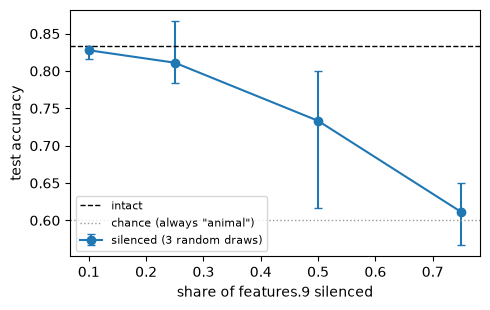

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.errorbar(dose.index, dose['mean'], yerr=[dose['mean'] - dose['min'], dose['max'] - dose['mean']],
            marker='o', capsize=3, label='silenced (3 random draws)')
ax.axhline(accuracy(intact), color='k', ls='--', lw=1, label='intact')
ax.axhline(0.6, color='0.6', ls=':', lw=1, label='chance (always "animal")')
ax.set_xlabel('share of features.9 silenced'); ax.set_ylabel('test accuracy')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

How quickly accuracy falls, and whether it falls before half the layer is gone, is the network's robustness to this lesion. Undoing every change restores exactly the intact answers.

## Summary

- `Selection` says which units, `Perturbation` what to do, `StateChange` applies or undoes.
- Fit the readout on the intact network, test the damaged one, and always undo (`reset()`).
- Random draws give the spread; [Lesson 8](08_choose_units.ipynb) chooses units by what they respond to.